![MOMENTUM · Hackatón de DRL · Entrenamiento](img/banner-train.jpg)

# **Código para el entrenamiento del agente**

Este cuaderno contiene el código necesario para entrenar un agente de [Stable Baselines 3](https://stable-baselines3.readthedocs.io/en/master/) en un entorno de la colección [`highway-env`](https://highway-env.farama.org/).

Primero, importamos las librerías necesarias:

In [19]:
import gymnasium as gym
import highway_env

from stable_baselines3 import A2C, DQN, PPO
from matplotlib import pyplot as plt
%matplotlib inline

Dada la componente aleatoria del entrenamiento, fijamos una semilla para el agente y el sampler de Optuna. Esto permite repetir el experimento bajo las mismas condiciones. Aún así, no garantiza resultados idénticos entre distintas versiones de las librerías o hardware.

In [20]:
import random

# Fijar la semilla
seed = 42
random.seed(seed)

## **1. Entorno de entrenamiento**

### **1.1 Selección del entorno**

**Dado que el entrenamiento de los agentes puede llevar bastante tiempo, se recomienda utilizar una variante simplificada llamada [`highway-fast-v0`](https://highway-env.farama.org/environments/highway/#faster-variant)**, que permite entrenar hasta 15 veces más rápido. No obstante, la evaluación será en el entorno no simplificado (`highway-v0`). Si bien es cierto que **un agente entrenado en `highway-fast-v0` puede generalizar y comportarse bien en `highway-v0`**, se recomienda usar el entorno simplificado para los entrenamientos más costosos (probar distintos algoritmos, ajustar hiperparámetros) y, una vez encontrada una buena configuración para el entrenamiento, entrenar el modelo definitivo en el entorno no simplificado, siempre y cuando sea posible por cuestiones de tiempo.

In [21]:
# Indica el entorno para el entrenamiento. Puedes cambiarlo por otro entorno de highway-env si lo deseas.
TRAIN_ENV_NAME = 'highway-fast-v0'

Dicho esto, visualizamos una instancia del entorno donde se va a entrenar el agente.

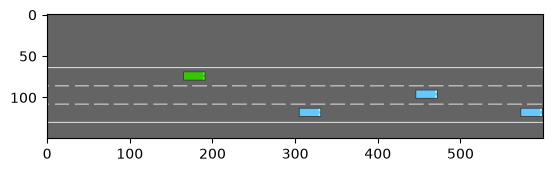

In [22]:
# Crear el entorno
env = gym.make(TRAIN_ENV_NAME, render_mode='rgb_array')

# Fijar una semilla para reproducibilidad
env.reset(seed=seed)

# Mostrar el estado inicial
plt.imshow(env.render())
plt.show()

A continuación, se muestran el espacio de observaciones y el espacio de acciones por defecto.

In [23]:
# Espacio de observaciones
print("Espacio de observaciones:", env.observation_space)

# Espacio de acciones
print("Espacio de acciones:", env.action_space)

# Se cierra el entorno de ejemplo
env.close()

Espacio de observaciones: Box(-inf, inf, (5, 5), float32)
Espacio de acciones: Discrete(5)


### **1.2 Configuración del entorno y wrappers**

En la función `make_env` se indica el entorno que vamos a utilizar para el entrenamiento. En el parámetro `config`, puedes modificar aspectos relativos a la dificultad del entorno (número de carriles, densidad de vehículos, etc.) así como la función de recompensa (penalización por colisión, bonificación por velocidad, etc.). Puedes consultar la configuración por defecto en la [documentación](https://highway-env.farama.org/environments/highway/). Ten en cuenta que el agente se evaluará con una configuración similar a la que hay por defecto, por lo que, si cambias la configuración, **no debes generar incompatibilidades**. Si tienes dudas sobre si algún cambio puede generar incompatibilidades, consulta a los mentores.

Una vez configurado el entorno, definimos los wrappers que consideremos necesarios y los llamamos en la función `aplicar_wrappers`. **Es importante tener en cuenta en qué orden se aplican, y mantener el mismo orden tanto en la evaluación como en la entrega final**. Recuerda que puedes consultar la documentación de los wrappers [aquí](https://gymnasium.farama.org/api/wrappers).

In [24]:
# Wrapper no frenar
class NonStopWrapper(gym.ActionWrapper):
    """
    Clase `NonStopWrapper`. impide que el modelo frene
    """

    # Aqui se define como se manipulan las acciones del agente
    def action(self, action):
        if action == 4:
            action = 1
        elif action == 1:
            action = 3
        return action

In [25]:
# # Wrapper no frenar
# class NonStopWrapper(gym.ActionWrapper):
#     """
#     Clase `NonStopWrapper`. impide que el modelo frene
#     """

#     # Aqui se define como se manipulan las acciones del agente
#     def action(self, action):
#         if action == 3:
#             action = 1
#         # elif action == 1:
#         #     action = 4
#         return action

In [26]:
# Define tus wrappers aqui

# class wrapper_1(gym.ObservationWrapper):
# ...

# class wrapper_2(gym.ActionWrapper):
# ...


# Aplica aqui todos los wrappers en el orden que consideres adecuado
def aplicar_wrappers(env):
    # env = wrapper_1(env)
    # env = wrapper_2(env)
    env = NonStopWrapper(env)
    return env


# Centraliza aqui la configuracion y los wrappers de todos los entornos
def make_env():
    new_env = gym.make(TRAIN_ENV_NAME, render_mode='rgb_array',
                    #    config={
                    #         Aqui puedes modificar la configuracion del entorno
                    #         ...
                    #     },
                    )

    new_env = aplicar_wrappers(new_env)
    
    return new_env


***

## **2. Entrenamiento de los agentes**

Una vez definido el entorno y los wrappers, especificaremos la configuración para el entrenamiento de los agentes: número de episodios de entrenamiento, evaluación, combinaciones de hiperparámetros a probar, etc.

**<span style="color:red">¡Atención!</span> El código de las siguientes celdas guarda el mejor agente resultante en un archivo dentro de la carpeta `agentes/<EXPERIMENT_NAME>`. Si ya existe una carpeta con el mismo nombre, el agente resultante de la última ejecución sobreescribirá al anterior, así que recuerda cambiar el valor de la variable `EXPERIMENT_NAME` y ejecutar la celda cada vez que modifiques la configuración del entrenamiento.**

In [27]:
EXPERIMENT_NAME = "PPO-1000_episodes-fast_env" # Nombre del experimento para guardar resultados

**Las variables definidas en la siguiente celda no se deben modificar**:

In [28]:
# Variables fijas que NO deben ser modificadas
N_JOBS = 1 # Numero de trabajos en paralelo para Optuna
TIMESTEPS_PER_EPISODE = 30 if TRAIN_ENV_NAME == "highway-fast-v0" else 40 # Numero de pasos por episodio
EVAL_EPISODES = 10 # Numero de episodios que dura cada evaluacion

**Las siguientes variables sí deben ser ajustadas**:

In [29]:
# Variables que SI pueden ser modificadas
TRAIN_EPISODES = 1000 # Numero de episodios de entrenamiento
N_COMBINACIONES = 1 # Numero de combinaciones a explorar durante la optimizacion de hiperparametros

### **2.1 Definición de callbacks personalizados**

En la siguiente celda **definimos las clases** de los callbacks personalizados. Las **instancias** se crearán después, dentro de `objective`, para que cada entrenamiento tenga sus propios callbacks.

Para más información sobre callbacks personalizados, consulta [la documentación](https://stable-baselines3.readthedocs.io/en/master/guide/callbacks.html).

In [30]:
from stable_baselines3.common.callbacks import BaseCallback
from tqdm.std import tqdm

# Callback para mostrar una barra de progreso de texto durante el entrenamiento
class TextProgressBarCallback(BaseCallback):
    """
    Barra de progreso de texto para `learn()`. Hace lo mismo que `progress_bar=True`,
    que en VS Code necesita widgets de Jupyter y puede fallar.
    """
    def _on_training_start(self):
        self.bar = tqdm(total=self.locals["total_timesteps"], unit=" pasos")

    def _on_step(self):
        # Cada llamada es un paso de cada entorno en paralelo; SB3 puede pasarse un poco del total
        self.bar.update(min(self.training_env.num_envs, self.bar.total - self.bar.n))
        return True

    def _on_training_end(self):
        self.bar.close()


# Define aqui las clases de tus callbacks personalizados.
# No olvides instanciarlos mas adelante en la funcion objective.

# class MiCallback(BaseCallback):
#     ...

### **2.2 Definición del entrenamiento y de los hiperparámetros**

Definimos la función `objective(trial)`, que Optuna ejecutará una vez por cada combinación de hiperparámetros. En ella seleccionamos los hiperparámetros, creamos el agente e instanciamos los callbacks definidos en la celda anterior. Ten en cuenta que esta celda solo define la función; el estudio de Optuna se ejecuta en la siguiente celda.


In [31]:
import optuna
import numpy as np
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.vec_env import DummyVecEnv
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.callbacks import CallbackList, StopTrainingOnMaxEpisodes

import torch
from stable_baselines3.common.vec_env import SubprocVecEnv, DummyVecEnv

N_ENVS =  20  # roughly the number of physical CPU cores you can spare
torch.set_num_threads(1)  # avoid CPU oversubscription (workers + torch threads)

def make_train_env(n_envs=N_ENVS):
    # Each worker gets its own Monitor so episode stats are tracked per env
    return SubprocVecEnv(
        [lambda: Monitor(make_env()) for _ in range(n_envs)],
        start_method="fork",   # Linux; avoids pickling issues in Jupyter
    )


# Semillas de validacion comunes a todos los trials, distintas de entrenamiento.
EVAL_SEEDS = [seed + 1000 + i for i in range(EVAL_EPISODES)]

# Diccionario para almacenar informacion sobre el mejor modelo entrenado
best_training_info = {}

# Definir la funcion para el/los entrenamiento/s
def objective(trial):

    # Hiperparametros a optimizar
    # learning_rate = trial.suggest_float(
    #     "learning_rate", 5e-4, 5e-3, log=True   # Si quieres modificar el learning rate, recuerda cambiar el rango de valores aqui. Actualmente esta fijo en 5e-4
    # )
    train_env = None
    eval_env = None

    try:
        # train_env = Monitor(make_env())
        train_env = make_train_env()
        eval_env = DummyVecEnv([lambda: Monitor(make_env())])

        # Crear agente
        # agent = PPO('MlpPolicy',
        #             train_env, # No modificar
        #             verbose=0, # No modificar
        #             seed=seed, # No modificar

        #             # Hiperparametros a optimizar
        #             learning_rate=learning_rate,
        #             # Resto de hiperparametros
        #             n_steps=n_steps,
        #             batch_size=batch_size,
        #             gamma=gamma,
        #             gae_lambda=gae_lambda,
        #             )

        agent = PPO.load(f"/home/coder/workspace/Need4Speed/logs/PPO/best_model.zip", env=train_env)


        # Instanciar los callbacks para este trial
        # stop_training_callback = StopTrainingOnMaxEpisodes(max_episodes=TRAIN_EPISODES, verbose=1) # Limita el numero de episodios al indicado
        stop_training_callback = StopTrainingOnMaxEpisodes(max_episodes=TRAIN_EPISODES * TIMESTEPS_PER_EPISODE, verbose=1) # Limita el numero de episodios al indicado
        text_progress_bar_callback = TextProgressBarCallback() # Muestra una barra de progreso de texto durante el entrenamiento

        # Instancia aqui las clases definidas en la celda de callbacks
        # custom_callback = MiCallback(...)


        # Lista de callbacks. Incluye aqui los callbacks que quieras aplicar.
        callbacks = CallbackList([
            stop_training_callback,
            text_progress_bar_callback,
            # custom_callback,
            # ...
        ])


        # Entrenamiento del agente
        agent.learn(total_timesteps=TRAIN_EPISODES * TIMESTEPS_PER_EPISODE,
                    callback=callbacks,
                    )


        # Evaluacion de la politica del agente
        episode_rewards = []
        for eval_seed in EVAL_SEEDS:
            eval_env.seed(eval_seed)
            rewards, _ = evaluate_policy(
                agent,
                eval_env,
                n_eval_episodes=1,
                deterministic=True,
                return_episode_rewards=True,
            )
            episode_rewards.extend(rewards)
        mean_reward = float(np.mean(episode_rewards))

        # Si el agente es el mejor hasta ahora, se guarda el agente junto con informacion relevante
        completed_trials = trial.study.get_trials(states=(optuna.trial.TrialState.COMPLETE,))
        
        if not completed_trials or mean_reward > trial.study.best_value:
            agent.save(f"agentes/{EXPERIMENT_NAME}/best_model.zip")

            # best_training_info.update({
            #     "rewards": np.asarray(train_env.get_episode_rewards()).copy(),
            #     "lengths": np.asarray(train_env.get_episode_lengths()).copy(),
            #     "trial_number": trial.number,
            #     "validation_mean_reward": mean_reward,
            # })
            rewards = np.concatenate(train_env.env_method("get_episode_rewards"))
            lengths = np.concatenate(train_env.env_method("get_episode_lengths"))

            best_training_info.update({
                "rewards": rewards.copy(),
                "lengths": lengths.copy(),
                "trial_number": trial.number,
                "validation_mean_reward": mean_reward,
            })

        # Se devuelve la recompensa media obtenida durante la evaluacion del agente entrenado
        return mean_reward

    finally:
        if eval_env is not None:
            eval_env.close()
        if train_env is not None:
            train_env.close()


### **2.3 Ejecución del entrenamiento**

Una vez definidos los callbacks y la función `objective`, creamos el estudio de Optuna y lanzamos los entrenamientos. Cada llamada a `objective` crea un agente y nuevas instancias de sus callbacks.

Si modificas una clase de callback, vuelve a ejecutar su celda antes de lanzar de nuevo el estudio. Si cambias los parámetros de sus instancias o la lista de callbacks, vuelve a ejecutar también la celda de `objective`.


In [32]:
import time

# Crear estudio de Optuna
study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=seed, n_startup_trials=N_COMBINACIONES//3),
)

# Guardar la hora de inicio
start_time = time.time()

# Ejecutar entrenamiento
study.optimize(objective, n_trials=N_COMBINACIONES, n_jobs=N_JOBS)

# Guardar la hora de finalizacion
end_time = time.time()

[I 2026-10-27 15:25:55,866] A new study created in memory with name: no-name-72abbb57-aed5-48bd-a566-adca85868727
100%|██████████| 30000/30000 [02:00<00:00, 248.04 pasos/s]
[I 2026-10-27 15:27:58,530] Trial 0 finished with value: 8.5718095 and parameters: {}. Best is trial 0 with value: 8.5718095.


 Una vez finalizado el entrenamiento, se muestra su duración, la mejor combinación de hiperparámetros explorada y la recompensa obtenida con dicha combinación. Esta información también se escribe en el archivo `agentes/<EXPERIMENT_NAME>/info_train.txt`.

In [33]:
# Mostrar informacion sobre el entrenamiento
print(f"El entrenamiento {EXPERIMENT_NAME} ha durado {end_time - start_time:.2f} segundos.")
print(f"Mejor recompensa obtenida: {study.best_value:.2f}")
print(f"Se han probado {N_COMBINACIONES} combinaciones de hiperparametros.")
print(f"Mejores hiperparametros:\n{study.best_params}")


# Escribir informacion util sobre el entrenamiento en un archivo de texto
with open(f"./agentes/{EXPERIMENT_NAME}/info_train.txt", "w") as f:
    f.write(f"Informacion sobre el experimento {EXPERIMENT_NAME}\n")
    f.write(f"\n - Duracion: {end_time - start_time:.2f} segundos.")
    f.write(f"\n - La mejor recompensa obtenida ha sido: {study.best_value:.2f}")
    f.write(f"\n - Se han probado {N_COMBINACIONES} combinaciones de hiperparametros.")
    f.write(f"\n - Los hiperparametros del mejor modelo encontrado son:\n\t{study.best_params}")


El entrenamiento PPO-1000_episodes-fast_env ha durado 122.66 segundos.
Mejor recompensa obtenida: 8.57
Se han probado 1 combinaciones de hiperparametros.
Mejores hiperparametros:
{}


A continuación, graficamos la evolución de la recompensa obtenida por el mejor agente a lo largo de los episodios. Esto nos permite comprobar si el aprendizaje llega a converger y cuándo lo hace, además de comprobar cuántos episodios son necesarios para el entrenamiento. Dicho gráfico se guarda en `agentes/<EXPERIMENT_NAME>/reward_evolution.png`.

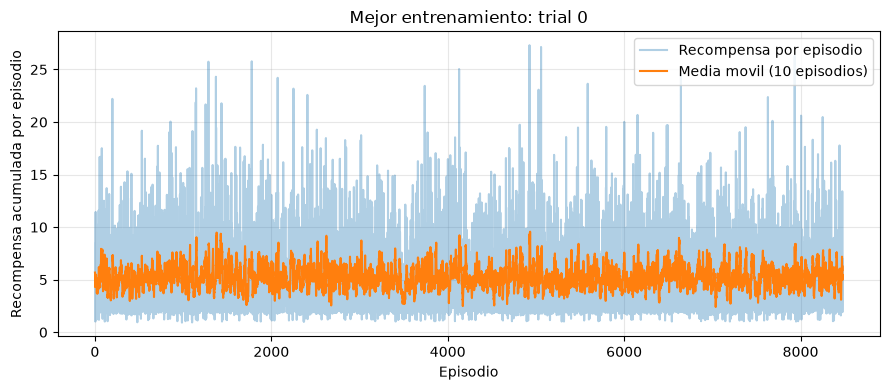

In [34]:
# Evolucion de la recompensa durante el entrenamiento del mejor trial.
WINDOW = 10  # Numero de episodios para la media movil
training_rewards = best_training_info["rewards"]
training_episodes = np.arange(1, len(training_rewards) + 1)


# Calcular la media movil de la recompensa obtenida
rolling_mean = np.array([
    training_rewards[max(0, i - WINDOW + 1):i + 1].mean()
    for i in range(len(training_rewards))
])

# Graficar la evolucion de la recompensa durante el entrenamiento
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(training_episodes, training_rewards, alpha=0.35, label="Recompensa por episodio")
ax.plot(training_episodes, rolling_mean, label=f"Media movil ({WINDOW} episodios)")
ax.set_xlabel("Episodio")
ax.set_ylabel("Recompensa acumulada por episodio")
ax.set_title(f"Mejor entrenamiento: trial {best_training_info['trial_number']}")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.savefig(f'agentes/{EXPERIMENT_NAME}/reward_evolution.png')
plt.show()
plt.close(fig)

In [35]:
best_training_info


{'rewards': array([5.67930699, 5.51264102, 1.91515275, ..., 3.85166104, 6.98415842,
        1.97966736], shape=(8477,)),
 'lengths': array([7, 7, 3, ..., 5, 9, 3], shape=(8477,)),
 'trial_number': 0,
 'validation_mean_reward': 8.5718095}

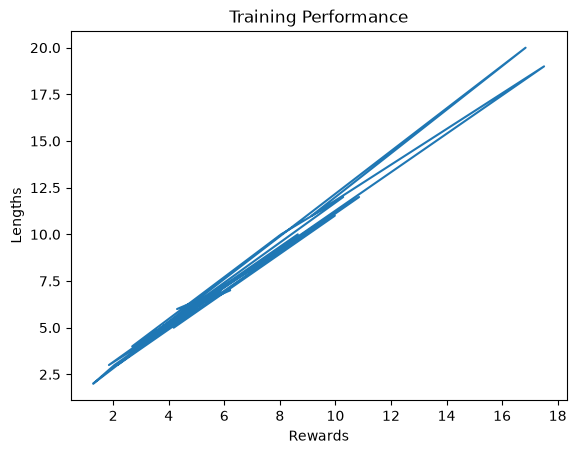

In [36]:
best_training_info
# plot x rewards y lengths
import matplotlib.pyplot as plt

plt.plot(best_training_info["rewards"][70:100], best_training_info["lengths"][70:100])
plt.xlabel("Rewards")
plt.ylabel("Lengths")
plt.title("Training Performance")
plt.show()


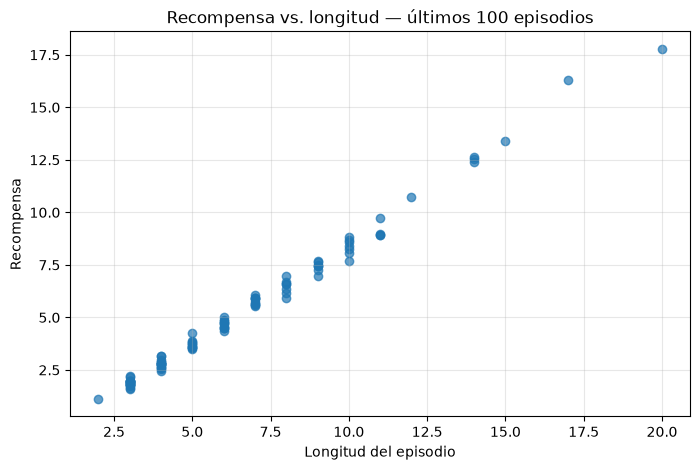

In [38]:
n_ultimos = 100
longitudes = best_training_info["lengths"][-n_ultimos:]
recompensas = best_training_info["rewards"][-n_ultimos:]

plt.figure(figsize=(8, 5))
plt.scatter(longitudes, recompensas, alpha=0.7)
plt.xlabel("Longitud del episodio")
plt.ylabel("Recompensa")
plt.title(f"Recompensa vs. longitud — últimos {len(longitudes)} episodios")
plt.grid(alpha=0.3)
plt.show()


Estos resultados se obtienen durante el entrenamiento. Sin embargo, **para medir el desempeño del mejor agente de forma justa, se debe evaluar en un entorno diferente**. Para ello, utiliza el **[notebook de test](test.ipynb)**. En él, encontrarás el código necesario para evaluar un agente ya entrenado, además de la obtención de métricas que facilitan el análisis de la política aprendida.